# Phase 2 — RF-DETR Training, Evaluation & Error Analysis

**Low-Light Object Detection via Decoupled VLM Pseudo-Labelling**

Trains structurally identical RF-DETR models on the three Phase 1 conditions and tests the
`C ≥ B > A` hypothesis. Condition C is run at **both 0.55 and 0.60** to settle the threshold
question Phase 1 left open (its F1 optimum sat on the sweep boundary). Empty-pseudo-label train
images are **dropped by default**.

Beyond headline mAP, every test detection is persisted with its matched-GT IoU so the failure
modes can be inspected directly.



## 1. Install RF-DETR and verify

`[train,loggers]` supplies Lightning + the TensorBoard logger; `.train()` fails at import without them.
`ultralytics` is needed in §10 to run the teacher on the test split.


In [1]:
!pip install -q "rfdetr[train,loggers]" supervision pycocotools ultralytics

ok = True
try:
    import rfdetr
    print("rfdetr           :", getattr(rfdetr, "__version__", "unknown"))
except Exception as e:
    ok = False; print("rfdetr import FAILED:", e)
try:
    import pytorch_lightning
    print("pytorch_lightning:", pytorch_lightning.__version__, "(training deps OK)")
except ModuleNotFoundError:
    ok = False; print("pytorch_lightning MISSING — rerun this cell.")
import torch
print("torch            :", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU              :", torch.cuda.get_device_name(0))
assert ok, ("Training deps missing. If this fired right after install: "
            "Runtime -> Restart session, then run this cell FIRST.")
print("\nSection 1 OK.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 5.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.2/280.2 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.1/588.1 kB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.4/852.4 kB 63.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 69.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 62.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 2. Configuration

`drop_empty_train=True` is the default for every Condition C variant. `C@0.55_keepempty` is kept in the
run plan as the controlled ablation that measures what dropping actually bought.


In [7]:
import os
from dataclasses import dataclass

RUN_TAG = "yoloworld_v8"

@dataclass
class P2Config:
    drive_root: str = "/content/drive/MyDrive/ExDark_dataset"
    manifest_path: str = (f"/content/drive/MyDrive/ExDark_dataset/phase1_outputs_{RUN_TAG}"
                          "/phase1_manifest.json")

    work_root:   str = "/content/phase2_datasets"
    ckpt_root:   str = f"/content/drive/MyDrive/ExDark_dataset/phase2_checkpoints_{RUN_TAG}"
    results_dir: str = f"/content/drive/MyDrive/ExDark_dataset/phase2_results_{RUN_TAG}"

    # ── shared training hyperparameters (identical across every condition) ──
    epochs: int = 25
    lr: float = 1e-4
    seed: int = 42
    early_stopping: bool = True
    resolution: int = 0            # 0 -> RF-DETR default (560); if set, must be divisible by 56

    # ── evaluation ──
    eval_conf: float = 0.01        # low, so the precision-recall curve is complete for COCOeval
    max_detections: int = 100
    iou_match: float = 0.50        # IoU that counts a detection as matching a GT box

    # ── Condition C ──
    c_thresholds: tuple = (0.55, 0.60)   # both trained, to settle the Phase 1 boundary result
    drop_empty_train: bool = True        # DEFAULT: drop train images with zero pseudo-labels

    run_plan: tuple = ("A", "B", "C@0.55", "C@0.60")

    # ── error analysis ──
    low_iou_max: float = 0.50      # detections below this IoU = localization failures
    low_conf_max: float = 0.30     # correct detections below this score = weak-confidence hits
    run_teacher_on_test: bool = True   # §10: YOLO-World on test, to find student-only discoveries

CFG = P2Config()
for d in (CFG.work_root, CFG.ckpt_root, CFG.results_dir):
    os.makedirs(d, exist_ok=True)

def batch_config():
    name = torch.cuda.get_device_name(0).lower() if torch.cuda.is_available() else ""
    if "a100" in name or "h100" in name: return 16, 1
    if "l4" in name or "a10" in name or "v100" in name: return 8, 2
    return 4, 4
BATCH_SIZE, GRAD_ACCUM = batch_config()

print(f"Effective batch 16 -> batch_size={BATCH_SIZE}, grad_accum_steps={GRAD_ACCUM}")
print("Epochs:", CFG.epochs, "| drop_empty_train:", CFG.drop_empty_train)
print("Run plan:", CFG.run_plan)
print("Results ->", CFG.results_dir)


Effective batch 16 -> batch_size=16, grad_accum_steps=1
Epochs: 25 | drop_empty_train: True
Run plan: ('A', 'B', 'C@0.55', 'C@0.60')
Results -> /content/drive/MyDrive/ExDark_dataset/phase2_results_yoloworld_v8


## 3. Mount Drive & load the Phase 1 handoff

Reads `phase1_manifest.json` from `phase1_outputs_yoloworld_v8/`, which carries the class list, the
enhanced pool location, the pseudo-label bank, and the persisted dataset zips.


In [3]:
import json, glob, time
from google.colab import drive

def robust_mount(mountpoint="/content/drive", tries=3):
    for i in range(tries):
        try:
            drive.mount(mountpoint, force_remount=True); return
        except ValueError as e:
            print(f"[mount] attempt {i+1} failed: {e}")
            os.system(f"fusermount -u {mountpoint} 2>/dev/null")
            os.system(f"rm -rf {mountpoint}")
            time.sleep(3)
    drive.mount(mountpoint)

robust_mount()

def load_manifest(cfg):
    cands = [cfg.manifest_path]
    cands += sorted(glob.glob(os.path.join(cfg.drive_root, "**", "phase1_manifest.json"),
                              recursive=True))
    path = next((p for p in cands if os.path.isfile(p)), None)
    if path is None:
        raise FileNotFoundError("phase1_manifest.json not found — run Phase 1's persist step.")
    m = json.load(open(path)); print("[manifest] loaded from", path); return m

M = load_manifest(CFG)
CLASSES = M["classes"]
print("Teacher            :", M.get("teacher"), "|", M.get("teacher_weights"))
print("Phase 1 recommended:", M.get("recommended_threshold"))
print("Classes            :", CLASSES)
print("Enhanced pool      :", M["enhanced_pool_dir"])
print("Pseudo-label bank  :", M["pseudo_label_bank"])
print("Zips               :", M["dataset_zip_dir"])


[mount] attempt 1 failed: Mountpoint must not already contain files
Mounted at /content/drive
[manifest] loaded from /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8/phase1_manifest.json
Teacher            : YOLO-World | yolov8x-worldv2.pt
Phase 1 recommended: 0.55
Classes            : ['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']
Enhanced pool      : /content/drive/MyDrive/ExDark_dataset/ExDark_enhanced
Pseudo-label bank  : /content/drive/MyDrive/ExDark_dataset/phase1_outputs_yoloworld_v8/pseudo_label_bank
Zips               : /content/drive/MyDrive/ExDark_dataset/phase1_datasets_zip_yoloworld_v8


## 4. Build the datasets

A and B unzip directly. Each C variant reuses B's enhanced images and swaps in the bank's train
annotations for that threshold — no re-inference. Dropping empty train images removes the
zero-pseudo-label images that would otherwise train the detector as pure negatives; the counts printed
here quantify how much supervision each variant actually carries.


In [8]:
import zipfile, shutil

def unzip_dataset(name, dest_root, manifest):
    dest = os.path.join(dest_root, name)
    if os.path.isfile(os.path.join(dest, "train", "_annotations.coco.json")):
        print(f"[data] {name}: already present"); return dest
    zpath = (manifest.get("persisted_zips", {}) or {}).get(name) or \
            os.path.join(manifest["dataset_zip_dir"], name + ".zip")
    if not os.path.isfile(zpath):
        raise FileNotFoundError(f"{name}: zip not found ({zpath})")
    print(f"[data] unzipping {name} ..."); t = time.time()
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(dest)
    print(f"[data]   done in {time.time()-t:.0f}s")
    return dest

def _copy_split(src_dir, dest, splits=("valid", "test")):
    for split in splits:
        s, d = os.path.join(src_dir, split), os.path.join(dest, split)
        if os.path.isdir(s) and not os.path.isdir(d):
            shutil.copytree(s, d)

def build_C(threshold, B_dir, dest_root, manifest, drop_empty=True, name=None):
    """Condition C at a threshold: B's enhanced images + bank pseudo-labels for train.
    drop_empty removes train images carrying zero pseudo-labels."""
    ttag = int(round(threshold * 100))
    name = name or (f"C_enh_vlm_t{ttag}" + ("" if drop_empty else "_keepempty"))
    dest = os.path.join(dest_root, name)
    if os.path.isfile(os.path.join(dest, "train", "_annotations.coco.json")):
        print(f"[data] {name}: already built"); return dest

    bank_json = os.path.join(manifest["pseudo_label_bank"],
                             f"train_enhanced_vlm_t{ttag}.coco.json")
    if not os.path.isfile(bank_json):
        raise FileNotFoundError(f"{name}: bank JSON missing ({bank_json})")

    print(f"[data] building {name} (drop_empty={drop_empty}) ..."); t = time.time()
    _copy_split(B_dir, dest)                       # valid/test = human labels on enhanced images
    coco = json.load(open(bank_json))
    n_img_all = len(coco["images"])

    if drop_empty:
        with_ann = {a["image_id"] for a in coco["annotations"]}
        keep = [im for im in coco["images"] if im["id"] in with_ann]
        keep_ids = {im["id"] for im in keep}
        coco = {"images": keep,
                "annotations": [a for a in coco["annotations"] if a["image_id"] in keep_ids],
                "categories": coco["categories"]}

    tr_dst = os.path.join(dest, "train"); os.makedirs(tr_dst, exist_ok=True)
    src_tr = os.path.join(B_dir, "train")
    missing = 0
    for im in coco["images"]:
        s, d = os.path.join(src_tr, im["file_name"]), os.path.join(tr_dst, im["file_name"])
        if os.path.isfile(s):
            if not os.path.exists(d): shutil.copy2(s, d)
        else:
            missing += 1
    json.dump(coco, open(os.path.join(tr_dst, "_annotations.coco.json"), "w"))
    dropped = n_img_all - len(coco["images"])
    print(f"[data]   {name}: train {len(coco['images'])} imgs "
          f"({dropped} empty dropped) / {len(coco['annotations'])} boxes"
          + (f" | {missing} images missing from B" if missing else "")
          + f" | {time.time()-t:.0f}s")
    return dest

# ── build everything in the run plan ──
DATASETS = {}
DATASETS["A"] = unzip_dataset("A_raw_human", CFG.work_root, M)
B_dir = unzip_dataset("B_enh_human", CFG.work_root, M)
DATASETS["B"] = B_dir

for thr in CFG.c_thresholds:
    DATASETS[f"C@{thr:.2f}"] = build_C(thr, B_dir, CFG.work_root, M,
                                       drop_empty=CFG.drop_empty_train)


print("\nDatasets built:", list(DATASETS.keys()))


[data] A_raw_human: already present
[data] B_enh_human: already present
[data] C_enh_vlm_t55: already built
[data] C_enh_vlm_t60: already built

Datasets built: ['A', 'B', 'C@0.55', 'C@0.60']


### 4.1 Normalize to the Roboflow convention & verify

RF-DETR expects a placeholder category 0 plus classes 1…12. The verification table is the last chance to
catch a mismatched split before an hour of training.


In [9]:
def normalize_coco_for_rfdetr(dataset_dir, classes):
    cats = [{"id": 0, "name": "exdark", "supercategory": "none"}] + \
           [{"id": i + 1, "name": c, "supercategory": "exdark"} for i, c in enumerate(classes)]
    name_to_id = {c: i + 1 for i, c in enumerate(classes)}
    for split in ["train", "valid", "test"]:
        jp = os.path.join(dataset_dir, split, "_annotations.coco.json")
        if not os.path.isfile(jp): continue
        coco = json.load(open(jp))
        if any(a["category_id"] not in name_to_id.values() for a in coco.get("annotations", [])):
            old = {c["id"]: c["name"] for c in coco.get("categories", [])}
            for a in coco["annotations"]:
                nm = old.get(a["category_id"])
                if nm in name_to_id: a["category_id"] = name_to_id[nm]
        coco["categories"] = cats
        json.dump(coco, open(jp, "w"))

for tag, d in DATASETS.items():
    normalize_coco_for_rfdetr(d, CLASSES)
print("[normalize] all datasets set to the Roboflow convention.\n")

import pandas as pd
def dataset_stats(d):
    out = {}
    for split in ["train", "valid", "test"]:
        jp = os.path.join(d, split, "_annotations.coco.json")
        if os.path.isfile(jp):
            c = json.load(open(jp))
            out[f"{split}_imgs"] = len(c["images"]); out[f"{split}_boxes"] = len(c["annotations"])
    return out

DS_STATS = pd.DataFrame({t: dataset_stats(d) for t, d in DATASETS.items()}).T
print("Verification (images / annotations):")
display(DS_STATS)

# val/test must be identical across conditions, or mAP is not comparable
_ref = DS_STATS.iloc[0]
for t in DS_STATS.index:
    for col in ["valid_imgs", "valid_boxes", "test_imgs", "test_boxes"]:
        if DS_STATS.loc[t, col] != _ref[col]:
            print(f"[WARN] {t}.{col}={DS_STATS.loc[t, col]} differs from {_ref.name} "
                  f"({_ref[col]}) — mAP will not be comparable across runs.")
print("[check] val/test consistency verified.")


[normalize] all datasets set to the Roboflow convention.

Verification (images / annotations):


,train_imgs,train_boxes,valid_imgs,valid_boxes,test_imgs,test_boxes
A,5886,19105,729,2387,748,2218
B,5886,19105,729,2387,748,2218
C@0.55,5134,13366,729,2387,748,2218
C@0.60,5012,12200,729,2387,748,2218


[check] val/test consistency verified.


## 5. Train

`RFDETRSmall` (the 29M model marketed as "Base"). Identical hyper-parameters across every run, so the
only variable is the training annotations. Completed runs skip via `.done`; interrupted runs resume.


In [10]:
from rfdetr import RFDETRSmall

BEST_NAMES   = ["checkpoint_best_ema.pth", "checkpoint_best_total.pth", "checkpoint_best_regular.pth"]
RESUME_NAMES = ["last.ckpt", "checkpoint.pth", "checkpoint_best_total.pth",
                "checkpoint_best_ema.pth", "checkpoint_best_regular.pth"]

def _first_existing(out_dir, names):
    for n in names:
        p = os.path.join(out_dir, n)
        if os.path.isfile(p): return p
    hits = sorted(glob.glob(os.path.join(out_dir, "checkpoint_best*.pth")))
    return hits[0] if hits else None

def _ckpt_dir(tag):
    return os.path.join(CFG.ckpt_root, tag.replace("@", "_").replace(".", "").replace("+", ""))

def train_run(tag, dataset_dir, cfg):
    out_dir = _ckpt_dir(tag); os.makedirs(out_dir, exist_ok=True)
    if os.path.isfile(os.path.join(out_dir, ".done")):
        print(f"[train] {tag}: complete — skipping.")
        return out_dir, _first_existing(out_dir, BEST_NAMES)
    kwargs = dict(dataset_dir=dataset_dir, epochs=cfg.epochs, batch_size=BATCH_SIZE,
                  grad_accum_steps=GRAD_ACCUM, lr=cfg.lr, output_dir=out_dir,
                  early_stopping=cfg.early_stopping, tensorboard=True)
    if cfg.resolution: kwargs["resolution"] = cfg.resolution
    resume = _first_existing(out_dir, RESUME_NAMES); t = time.time()
    try:
        if resume:
            print(f"[train] {tag}: resuming from {os.path.basename(resume)}")
            RFDETRSmall().train(resume=resume, **kwargs)
        else:
            print(f"[train] {tag}: fresh ({cfg.epochs} epochs)")
            RFDETRSmall().train(**kwargs)
    except Exception as e:
        if resume:
            print(f"[train] {tag}: resume failed ({type(e).__name__}); restarting fresh.")
            RFDETRSmall().train(**kwargs)
        else:
            raise
    open(os.path.join(out_dir, ".done"), "w").write(str(cfg.epochs))
    print(f"[train] {tag}: finished in {(time.time()-t)/60:.1f} min")
    return out_dir, _first_existing(out_dir, BEST_NAMES)

RUN_CKPTS = {}
for tag in CFG.run_plan:
    if tag not in DATASETS:
        print(f"[train] {tag}: no dataset built — skipping."); continue
    out_dir, best = train_run(tag, DATASETS[tag], CFG)
    RUN_CKPTS[tag] = {"out_dir": out_dir, "best": best, "dataset": DATASETS[tag]}

print("\nRun status:")
for tag, info in RUN_CKPTS.items():
    print(f"  {tag:<20} done={os.path.isfile(os.path.join(info['out_dir'], '.done'))}  "
          f"best={os.path.basename(info['best']) if info['best'] else None}")


[train] A: resuming from checkpoint_best_ema.pth
[2026-08-01 08:37:29] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-08-01 08:37:29] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-01 08:37:29] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-08-01 08:37:31] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-08-01 08:37:32] [WARNING] rf-detr - Pretrained weights at '/root/.roboflow/models/rf-detr-small.pth' loaded only partially — this typically produces lower accuracy. 1 model parameter(s) not in checkpoint (left at random init): [_kp_active_mask]. Check that the model configuration (encoder, hidden_dim, out_feature_indexes, projector_scale, ...) matches the architecture the checkpoint was trained with.
[2026-08-01 08:37:32] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-01 08:37:32] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-08-01 08:37:34] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


...

[2026-08-01 11:00:22] [INFO] rf-detr - Best EMA mAP improved to 0.4254 (epoch 2)


INFO:pytorch_lightning.callbacks.early_stopping:Metric __rfdetr_effective_map__ improved by 0.006 >= min_delta = 0.001. New best score: 0.431


[2026-08-01 11:03:29] [INFO] rf-detr - Best regular checkpoint saved to /content/drive/MyDrive/ExDark_dataset/phase2_checkpoints_yoloworld_v8/C_060/checkpoint_best_regular.pth (epoch 3, monitor=val/mAP_50_95, value=0.424252)
[2026-08-01 11:03:29] [INFO] rf-detr - Best EMA mAP improved to 0.4312 (epoch 3)


INFO:pytorch_lightning.callbacks.early_stopping:Monitored metric __rfdetr_effective_map__ did not improve in the last 10 records. Best score: 0.431. Signaling Trainer to stop.


[2026-08-01 11:34:45] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.4243, ema=0.4312)
[train] C@0.60: finished in 44.0 min

Run status:
  A                    done=True  best=checkpoint_best_ema.pth
  B                    done=True  best=checkpoint_best_ema.pth
  C@0.55               done=True  best=checkpoint_best_ema.pth
  C@0.60               done=True  best=checkpoint_best_ema.pth


## 6. Plotting helper

`mark_axis_break` draws a double-slash on any axis that doesn't start at 0; `pad_for_break` shifts the
data up and right so the first tick clears the symbol. Call `pad_for_break` after all plotting and
before `mark_axis_break`.


In [11]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
sns.set_theme(style="whitegrid")

def mark_axis_break(ax, x=None, y=None, size=0.012, gap=0.010, pos=0.045, lw=1.2):
    """Double-slash break symbol on any axis whose lower limit is above 0."""
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    if x is None: x = xlim[0] > 1e-9
    if y is None: y = ylim[0] > 1e-9
    kw = dict(transform=ax.transAxes, color="black", clip_on=False,
              linewidth=lw, solid_capstyle="butt", zorder=10)
    if x:
        for off in (-gap / 2, gap / 2):
            ax.plot([pos + off - size, pos + off + size], [-size, size], **kw)
    if y:
        for off in (-gap / 2, gap / 2):
            ax.plot([-size, size], [pos + off - size, pos + off + size], **kw)
    return ax

def pad_for_break(ax, frac=0.10, x=True, y=True):
    """Pad the left/bottom so ticks clear the break symbols. Call after plotting."""
    if x:
        x0, x1 = ax.get_xlim(); ax.set_xlim(x0 - frac * (x1 - x0), x1)
    if y:
        y0, y1 = ax.get_ylim(); ax.set_ylim(y0 - frac * (y1 - y0), y1)
    return ax

def savefig(fig, name):
    os.makedirs(CFG.results_dir, exist_ok=True)
    fig.savefig(os.path.join(CFG.results_dir, name), dpi=130, bbox_inches="tight")


## 7. Convergence curves

Reads each run's `metrics.csv`. The diagnostic question: is Condition C still climbing at 25 epochs
(under-converged, train longer) or has it plateaued below B (structural coverage/localization limit)?


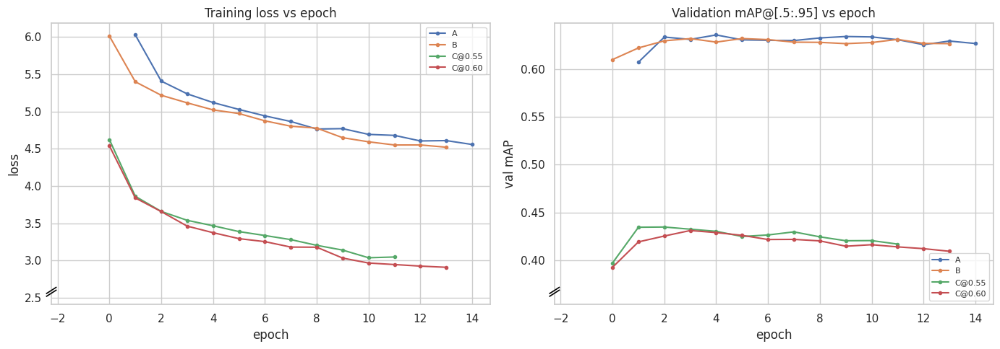

Final-epoch snapshot:
  A                    epoch=14  loss=4.5561  val_mAP=0.6268 (plateaued)
  B                    epoch=13  loss=4.5197  val_mAP=0.6267 (plateaued)
  C@0.55               epoch=11  loss=3.0467  val_mAP=0.417 (plateaued)
  C@0.60               epoch=13  loss=2.9083  val_mAP=0.4095 (plateaued)


In [12]:
import pandas as pd

def load_metrics(out_dir):
    fp = os.path.join(out_dir, "metrics.csv")
    if not os.path.isfile(fp):
        hits = sorted(glob.glob(os.path.join(out_dir, "**", "metrics.csv"), recursive=True))
        fp = hits[0] if hits else None
    if not fp: return None
    df = pd.read_csv(fp)
    if "epoch" in df.columns:
        df = df.groupby("epoch", as_index=False).mean(numeric_only=True)
    return df

def _pick(cols, must, avoid=()):
    for c in cols:
        cl = c.lower()
        if all(m in cl for m in must) and not any(a in cl for a in avoid):
            return c
    return None

CURVES = {}
for tag, info in RUN_CKPTS.items():
    df = load_metrics(info["out_dir"])
    if df is None:
        print(f"[curves] {tag}: metrics.csv not found"); continue
    cols = list(df.columns)
    CURVES[tag] = {
        "df": df,
        "loss":  _pick(cols, ["train", "loss"]) or _pick(cols, ["loss"], avoid=["val"]),
        "map":   _pick(cols, ["map", "50_95"]) or _pick(cols, ["map"], avoid=["50"]),
        "map50": _pick(cols, ["map_50"], avoid=["95"]) or _pick(cols, ["map50"]),
    }

if CURVES:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for tag, c in CURVES.items():
        df = c["df"]; x = df["epoch"] if "epoch" in df else range(len(df))
        if c["loss"]: axes[0].plot(x, df[c["loss"]], marker=".", label=tag)
        if c["map"]:  axes[1].plot(x, df[c["map"]],  marker=".", label=tag)
    axes[0].set_title("Training loss vs epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
    axes[0].legend(fontsize=8)
    axes[1].set_title("Validation mAP@[.5:.95] vs epoch"); axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("val mAP"); axes[1].legend(fontsize=8)
    for ax in axes:
        pad_for_break(ax); mark_axis_break(ax)
    plt.tight_layout(); savefig(fig, "convergence_curves.png"); plt.show()

    print("Final-epoch snapshot:")
    for tag, c in CURVES.items():
        df = c["df"]; last = df.iloc[-1]
        loss = round(float(last[c["loss"]]), 4) if c["loss"] else None
        vmap = round(float(last[c["map"]]), 4) if c["map"] else None
        ep = int(last["epoch"]) if "epoch" in df else len(df)
        # still-improving check: best val mAP in the last 3 epochs?
        trend = ""
        if c["map"] and len(df) >= 4:
            trend = " (still improving)" if df[c["map"]].idxmax() >= len(df) - 3 else " (plateaued)"
        print(f"  {tag:<20} epoch={ep}  loss={loss}  val_mAP={vmap}{trend}")
else:
    print("[curves] no metrics found.")


## 8. Evaluation with full detection dump

COCOeval with standard `maxDets=[1,10,100]`, reporting AP@0.5 and AP@[.5:.95] overall and per class.

Every detection is also greedily matched to ground truth and written to
`detections_<run>.parquet` with its confidence, best IoU, matched GT id, and TP/FP status — plus a
record of every **missed** GT box. This dump is what §9 and §11 analyse, and what Phase 2b needs.


In [13]:
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io as _io

def _load_model(best):
    try:    return RFDETRSmall.from_checkpoint(best)
    except Exception: return RFDETRSmall(pretrain_weights=best)

def _resolver(model, name_to_catid):
    names = getattr(model, "class_names", None)
    def r(cid, data):
        nm = None
        if isinstance(data, dict):
            a = data.get("class_name"); nm = a if isinstance(a, str) else None
        if nm is None and names is not None and 0 <= int(cid) < len(names):
            nm = names[int(cid)]
        if nm is not None:
            nm = str(nm)
            if nm in name_to_catid: return name_to_catid[nm]
            low = {k.lower(): v for k, v in name_to_catid.items()}
            if nm.lower() in low: return low[nm.lower()]
        if int(cid) in name_to_catid.values(): return int(cid)
        return int(cid) + 1
    return r

def _iou_xyxy(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    ua = max(0.0, a[2]-a[0]) * max(0.0, a[3]-a[1])
    ub = max(0.0, b[2]-b[0]) * max(0.0, b[3]-b[1])
    d = ua + ub - inter
    return inter / d if d > 0 else 0.0

def evaluate_run(tag, best, dataset_dir, cfg):
    """COCOeval metrics + a per-detection / per-missed-GT record dump."""
    test_dir = os.path.join(dataset_dir, "test")
    coco_gt = COCO(os.path.join(test_dir, "_annotations.coco.json"))
    cats = coco_gt.loadCats(coco_gt.getCatIds())
    name_to_catid = {c["name"]: c["id"] for c in cats if c["name"] != "exdark"}
    id_to_name = {c["id"]: c["name"] for c in cats}
    fname_to_id = {coco_gt.loadImgs(i)[0]["file_name"]: i for i in coco_gt.getImgIds()}

    model = _load_model(best); resolve = _resolver(model, name_to_catid)
    results, records = [], []

    for fn, img_id in fname_to_id.items():
        p = os.path.join(test_dir, fn)
        if not os.path.isfile(p): continue
        det = model.predict(Image.open(p).convert("RGB"), threshold=cfg.eval_conf)
        xyxy = getattr(det, "xyxy", None); conf = getattr(det, "confidence", None)
        cid  = getattr(det, "class_id", None); data = getattr(det, "data", {}) or {}
        n = 0 if xyxy is None else len(xyxy)
        order = np.argsort(-conf)[:cfg.max_detections] if (conf is not None and n) else range(n)

        # ground truth for this image
        gts = [{"id": a["id"], "cat": a["category_id"],
                "box": [a["bbox"][0], a["bbox"][1], a["bbox"][0]+a["bbox"][2], a["bbox"][1]+a["bbox"][3]]}
               for a in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id))]
        claimed = set()

        for k in order:
            x1, y1, x2, y2 = [float(v) for v in xyxy[k]]
            cname = data.get("class_name")[k] if isinstance(data, dict) and "class_name" in data else None
            catid = resolve(int(cid[k]), {"class_name": cname} if cname is not None else {})
            score = float(conf[k])
            results.append({"image_id": int(img_id), "category_id": int(catid),
                            "bbox": [x1, y1, x2-x1, y2-y1], "score": score})
            # greedy match against unclaimed same-class GT
            best_iou, best_gid = 0.0, None
            for g in gts:
                if g["cat"] != catid or g["id"] in claimed: continue
                v = _iou_xyxy([x1, y1, x2, y2], g["box"])
                if v > best_iou: best_iou, best_gid = v, g["id"]
            tp = best_iou >= cfg.iou_match and best_gid is not None
            if tp: claimed.add(best_gid)
            records.append({"run": tag, "image_id": int(img_id), "file_name": fn,
                            "kind": "detection", "cls": id_to_name.get(catid, str(catid)),
                            "score": score, "best_iou": best_iou, "tp": bool(tp),
                            "gt_id": best_gid if tp else None,
                            "x1": x1, "y1": y1, "x2": x2, "y2": y2})

        # every GT box the model never matched = a miss
        for g in gts:
            if g["id"] not in claimed:
                records.append({"run": tag, "image_id": int(img_id), "file_name": fn,
                                "kind": "missed_gt", "cls": id_to_name.get(g["cat"], str(g["cat"])),
                                "score": np.nan, "best_iou": np.nan, "tp": False,
                                "gt_id": g["id"],
                                "x1": g["box"][0], "y1": g["box"][1],
                                "x2": g["box"][2], "y2": g["box"][3]})

    if not results:
        print(f"[eval] {tag}: no detections."); return None

    coco_dt = coco_gt.loadRes(results)
    ev = COCOeval(coco_gt, coco_dt, "bbox"); ev.params.maxDets = [1, 10, 100]
    with contextlib.redirect_stdout(_io.StringIO()):
        ev.evaluate(); ev.accumulate(); ev.summarize()

    prec = ev.eval["precision"]; iou_thrs = ev.params.iouThrs
    idx50 = int(np.argmin(np.abs(iou_thrs - 0.5)))
    per, per50, ap_all, ap50_all = {}, {}, [], []
    for k, cid_ in enumerate(coco_gt.getCatIds()):
        nm = id_to_name.get(cid_, str(cid_))
        if nm == "exdark": continue
        pr = prec[:, :, k, 0, -1]; pr = pr[pr > -1]
        ap = float(pr.mean()) if pr.size else float("nan")
        pr5 = prec[idx50, :, k, 0, -1]; pr5 = pr5[pr5 > -1]
        ap5 = float(pr5.mean()) if pr5.size else float("nan")
        per[nm], per50[nm] = round(ap, 4), round(ap5, 4)
        if not np.isnan(ap):  ap_all.append(ap)
        if not np.isnan(ap5): ap50_all.append(ap5)

    metrics = {"mAP": round(float(np.mean(ap_all)), 4) if ap_all else None,
               "mAP50": round(float(np.mean(ap50_all)), 4) if ap50_all else None,
               "per_class": per, "per_class_50": per50}

    df = pd.DataFrame(records)
    os.makedirs(CFG.results_dir, exist_ok=True)
    dump_path = os.path.join(CFG.results_dir, f"detections_{tag.replace('@','_').replace('.','')}.parquet")
    df.to_parquet(dump_path, index=False)
    n_par = sum(p.numel() for p in model.model.model.parameters()) if hasattr(model, "model") else None

    print(f"[eval] {tag}: mAP@0.5={metrics['mAP50']}  mAP@[.5:.95]={metrics['mAP']}  "
          f"| {len(df[df.kind=='detection'])} dets, {len(df[df.kind=='missed_gt'])} missed GT "
          f"-> {os.path.basename(dump_path)}")
    return {"metrics": metrics, "params": n_par, "records": df, "dump": dump_path}

EVAL = {}
for tag, info in RUN_CKPTS.items():
    if not info["best"]:
        print(f"[eval] {tag}: no checkpoint — skipping."); continue
    r = evaluate_run(tag, info["best"], info["dataset"], CFG)
    if r: EVAL[tag] = r


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


/usr/local/lib/python3.12/dist-packages/rfdetr/detr.py:545: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.12/dist-packages/rfdetr/detr.py:545: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.12/dist-packages/rfdetr/detr.py:545: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-08-01 11:34:47] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-01 11:34:47] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

Loading and preparing results...
DONE (t=0.53s)
creating index...
index created!
[eval] A: mAP@0.5=0.8931  mAP@[.5:.95]=0.6339  | 69472 dets, 40 missed GT -> detections_A.parquet
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


[2026-08-01 11:35:28] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-01 11:35:28] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-01 11:35:28] [WARNING] rf-detr - load_pretrain_weights: checkpoint lacks args.num_queries / args.group_detr; falling back to flat slice. With group_detr=13 this may scramble per-group query structure if the checkpoint was trained with group_detr > 1.
[2026-08-01 11:35:28] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Loading and preparing results...
DONE (t=0.52s)
creating index...
index created!
[eval] B: mAP@0.5=0.8829  mAP@[.5:.95]=0.6208  | 66791 dets, 48 missed GT -> detections_B.parquet
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


[2026-08-01 11:36:22] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-01 11:36:22] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-01 11:36:22] [WARNING] rf-detr - load_pretrain_weights: checkpoint lacks args.num_queries / args.group_detr; falling back to flat slice. With group_detr=13 this may scramble per-group query structure if the checkpoint was trained with group_detr > 1.
[2026-08-01 11:36:22] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Loading and preparing results...
DONE (t=0.51s)
creating index...
index created!
[eval] C@0.55: mAP@0.5=0.7581  mAP@[.5:.95]=0.4203  | 69327 dets, 167 missed GT -> detections_C_055.parquet
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


[2026-08-01 11:37:16] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-01 11:37:16] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-01 11:37:17] [WARNING] rf-detr - load_pretrain_weights: checkpoint lacks args.num_queries / args.group_detr; falling back to flat slice. With group_detr=13 this may scramble per-group query structure if the checkpoint was trained with group_detr > 1.
[2026-08-01 11:37:17] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Loading and preparing results...
DONE (t=0.07s)
creating index...
index created!
[eval] C@0.60: mAP@0.5=0.7551  mAP@[.5:.95]=0.4164  | 66029 dets, 157 missed GT -> detections_C_060.parquet


## 9. Results summary

Headline mAP plus per-class AP in both IoU regimes. The tightness ratio (mAP@[.5:.95] / mAP@0.5)
separates *finding* objects from *localizing* them: a low ratio means boxes are found but loose.


=== Results (ExDark test split) ===


,Run,mAP@0.5,mAP@[.5:.95],tightness,train_imgs,train_boxes
0,A,0.8931,0.6339,0.710,5886,19105
1,B,0.8829,0.6208,0.703,5886,19105
2,C@0.55,0.7581,0.4203,0.554,5134,13366
3,C@0.60,0.7551,0.4164,0.551,5012,12200



=== Per-class AP@[.5:.95] ===


,Bicycle,Boat,Bottle,Bus,Car,Cat,Chair,Cup,Dog,Motorbike,People,Table
Run,,,,,,,,,,,,
A,0.6076,0.5524,0.6236,0.7837,0.6395,0.6364,0.6053,0.6282,0.7171,0.6697,0.5844,0.5589
B,0.5902,0.5234,0.6001,0.7962,0.6266,0.6230,0.5827,0.6117,0.6860,0.6615,0.5898,0.5585
C@0.55,0.4429,0.2025,0.3193,0.6500,0.4817,0.4441,0.4242,0.3773,0.4164,0.5143,0.4354,0.3352
C@0.60,0.4380,0.1975,0.3191,0.6425,0.4898,0.4377,0.4304,0.3755,0.4196,0.5158,0.4331,0.2972



=== Per-class AP@0.5 ===


,Bicycle,Boat,Bottle,Bus,Car,Cat,Chair,Cup,Dog,Motorbike,People,Table
Run,,,,,,,,,,,,
A,0.8771,0.8804,0.8894,0.9405,0.9100,0.9184,0.8758,0.8777,0.9314,0.9272,0.8972,0.7924
B,0.8785,0.8537,0.8680,0.9426,0.8955,0.9263,0.8477,0.8661,0.9207,0.9099,0.9021,0.7834
C@0.55,0.8187,0.5437,0.7248,0.9293,0.8152,0.7759,0.7596,0.7321,0.8514,0.8429,0.8026,0.5008
C@0.60,0.7803,0.5881,0.7031,0.9333,0.8169,0.7978,0.7577,0.7362,0.8429,0.8449,0.8073,0.4528


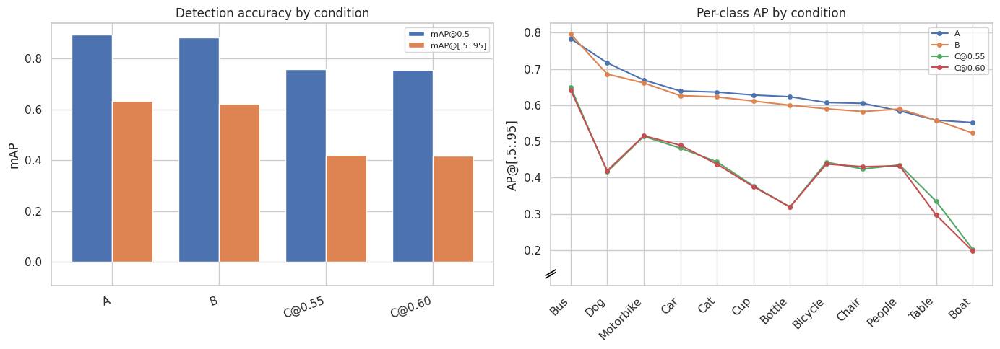

In [14]:
rows = []
for tag, e in EVAL.items():
    m = e.get("metrics") or {}
    tight = (m["mAP"] / m["mAP50"]) if (m.get("mAP") and m.get("mAP50")) else None
    rows.append({"Run": tag, "mAP@0.5": m.get("mAP50"), "mAP@[.5:.95]": m.get("mAP"),
                 "tightness": round(tight, 3) if tight else None,
                 "train_imgs": int(DS_STATS.loc[tag, "train_imgs"]) if tag in DS_STATS.index else None,
                 "train_boxes": int(DS_STATS.loc[tag, "train_boxes"]) if tag in DS_STATS.index else None})
SUMMARY = pd.DataFrame(rows).sort_values("mAP@[.5:.95]", ascending=False).reset_index(drop=True)
print("=== Results (ExDark test split) ===")
display(SUMMARY)

PER_CLASS    = pd.DataFrame([{"Run": t, **((e.get("metrics") or {}).get("per_class") or {})}
                             for t, e in EVAL.items()]).set_index("Run")
PER_CLASS_50 = pd.DataFrame([{"Run": t, **((e.get("metrics") or {}).get("per_class_50") or {})}
                             for t, e in EVAL.items()]).set_index("Run")
print("\n=== Per-class AP@[.5:.95] ==="); display(PER_CLASS)
print("\n=== Per-class AP@0.5 ===");      display(PER_CLASS_50)

# ── headline comparison plot ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
xs = np.arange(len(SUMMARY)); w = 0.38
ax.bar(xs - w/2, SUMMARY["mAP@0.5"], w, label="mAP@0.5")
ax.bar(xs + w/2, SUMMARY["mAP@[.5:.95]"], w, label="mAP@[.5:.95]")
ax.set_xticks(xs); ax.set_xticklabels(SUMMARY["Run"], rotation=20, ha="right")
ax.set_ylabel("mAP"); ax.set_title("Detection accuracy by condition"); ax.legend(fontsize=8)
pad_for_break(ax, x=False); mark_axis_break(ax)

ax = axes[1]
_pc = PER_CLASS.T.sort_values(PER_CLASS.index[0], ascending=False)
for tag in PER_CLASS.index:
    ax.plot(_pc.index, _pc[tag], marker="o", ms=4, label=tag)
ax.set_ylabel("AP@[.5:.95]"); ax.set_title("Per-class AP by condition")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend(fontsize=8)
pad_for_break(ax, x=False); mark_axis_break(ax)
plt.tight_layout(); savefig(fig, "results_summary.png"); plt.show()


## 10. Error analysis — where each model fails


Renders the flagged cases with **solid green = ground truth** and **dashed orange = prediction**, sorted
by how much larger the GT box is.

Missed-GT cases are rendered separately, since a "miss" against a badly drawn GT box means something
different from a real miss.


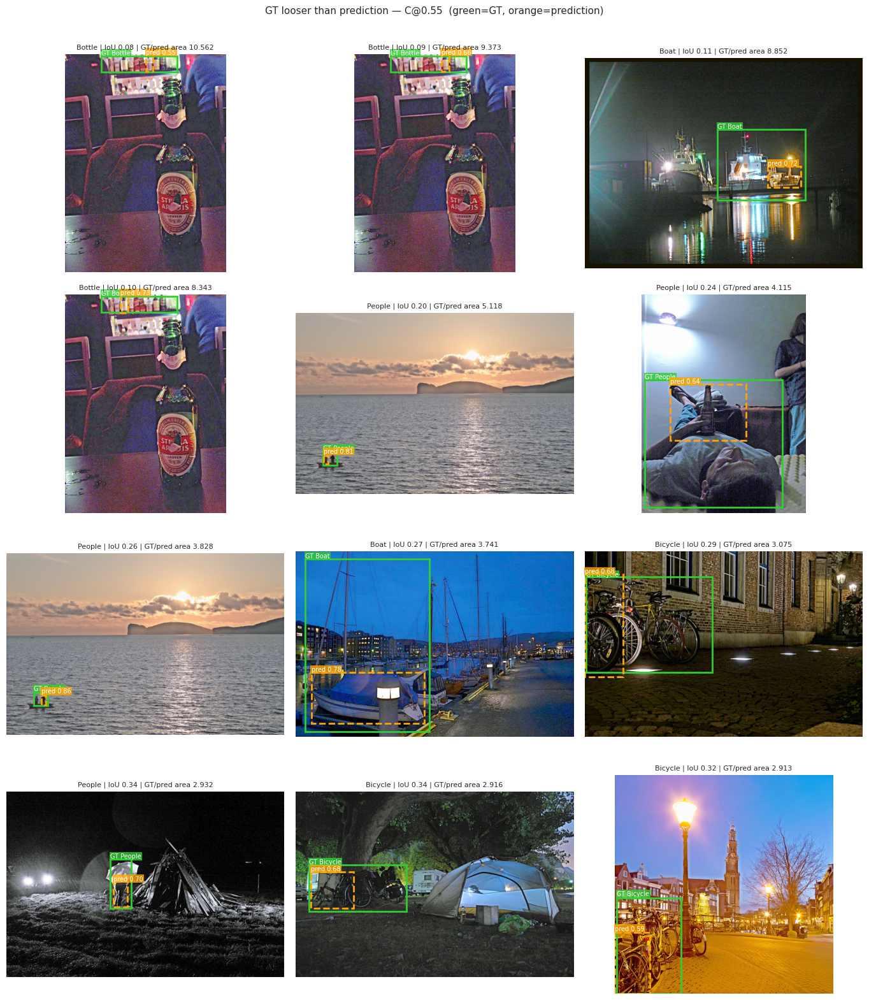

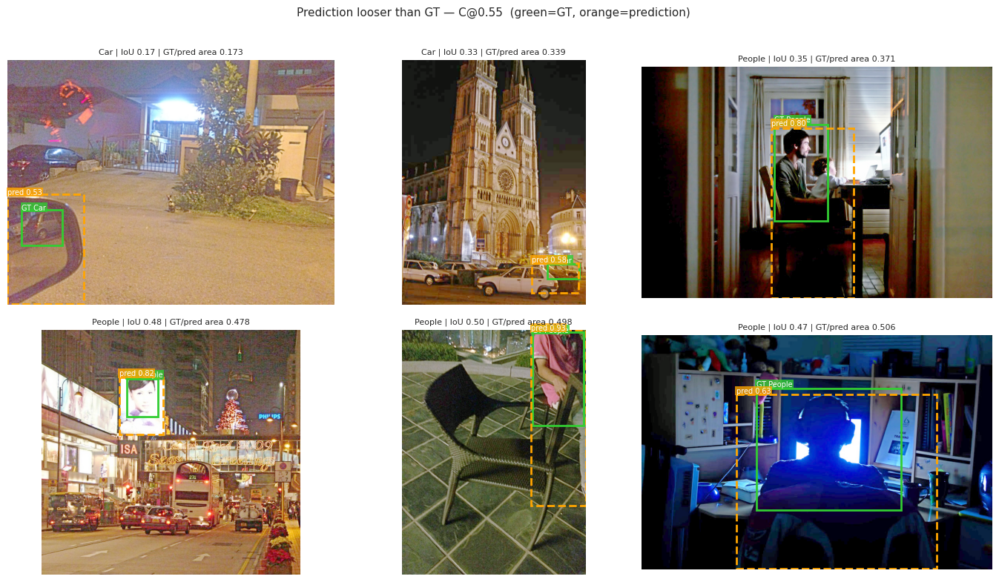

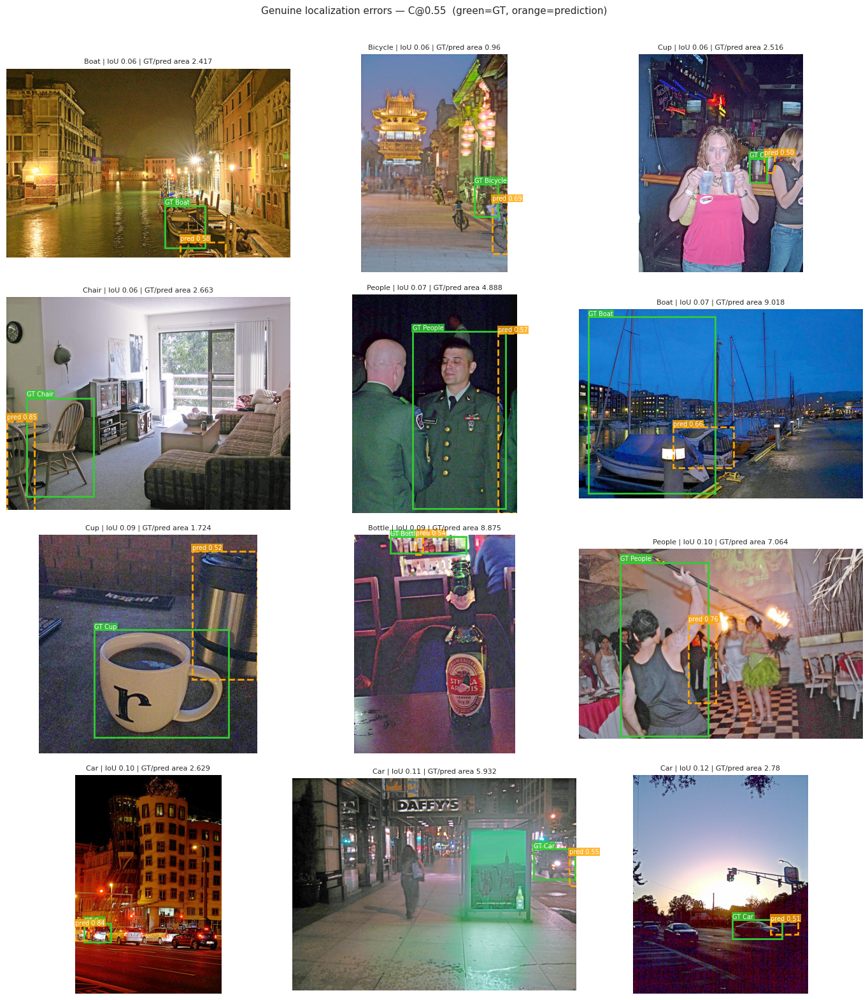

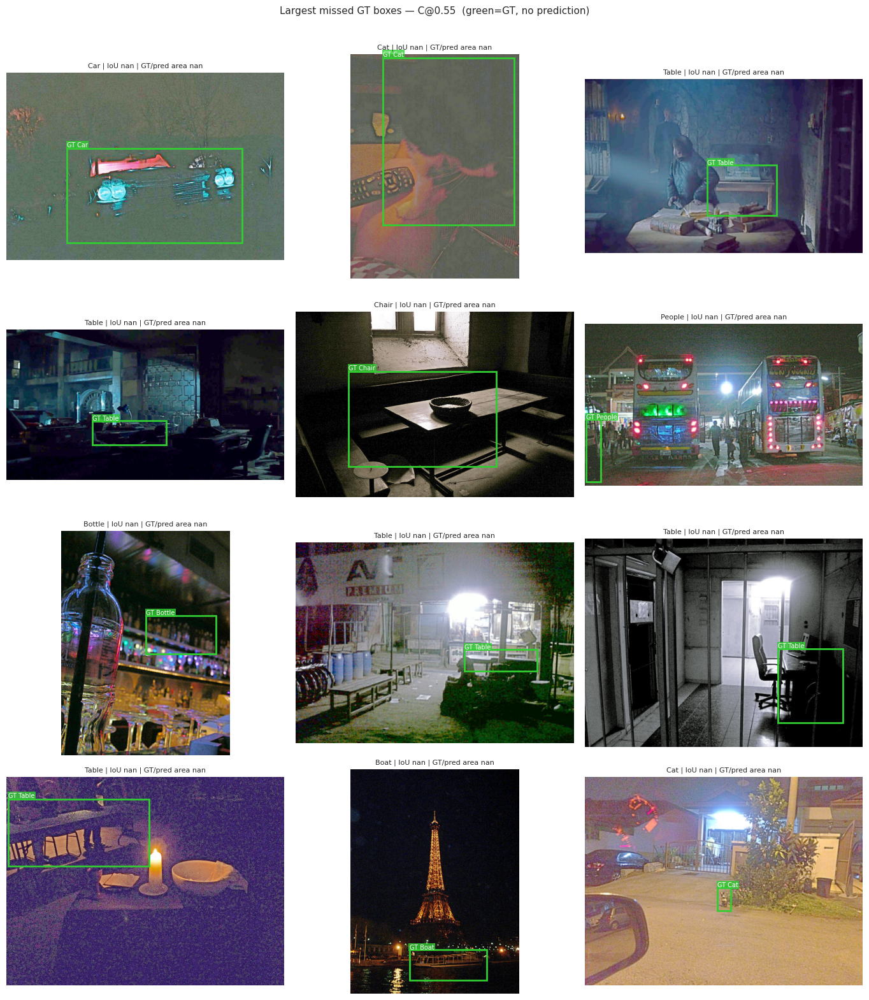


Missed GT: 167 boxes | median area 3640px^2 | most-missed classes: People, Boat, Bottle


In [ ]:
import matplotlib.patches as patches

_c_runs = [t for t in EVAL if t.startswith("C@")]
_focus = max(_c_runs, key=lambda t: EVAL[t]["metrics"]["mAP"]) if _c_runs else list(EVAL)[0]
print("Focus run:", _focus)

def _area(b): return max(0.0, b[2]-b[0]) * max(0.0, b[3]-b[1])
def _inter(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    return max(0.0, ix2-ix1) * max(0.0, iy2-iy1)
# ─────────────────────────────────────────────────────────────────────────────

N_PANELS = 12          # worst cases to render per category
PANEL_COLS = 3

def _draw(ax, img, boxes, title):
    ax.imshow(img)
    for label, box, color, ls in boxes:
        x1, y1, x2, y2 = box
        ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2.0,
                                       edgecolor=color, facecolor="none", linestyle=ls))
        ax.text(x1, max(y1-4, 0), label, color="white", fontsize=7,
                bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))
    ax.set_title(title, fontsize=8); ax.axis("off")

def render_cases(sub, dataset_dir, title, fname, n=N_PANELS):
    """Render GT (green, solid) vs prediction (orange, dashed) for the selected rows."""
    sub = sub.head(n)
    if not len(sub):
        print(f"[viz] {title}: nothing to render"); return
    test_dir = os.path.join(dataset_dir, "test")
    rows = int(np.ceil(len(sub) / PANEL_COLS))
    fig, axes = plt.subplots(rows, PANEL_COLS, figsize=(4.6*PANEL_COLS, 3.9*rows))
    axes = np.atleast_1d(axes).flatten()
    for ax, r in zip(axes, sub.itertuples()):
        p = os.path.join(test_dir, r.file_name)
        if not os.path.isfile(p):
            ax.axis("off"); continue
        img = Image.open(p).convert("RGB")
        boxes = [(f"GT {r.cls}", [r.gx1, r.gy1, r.gx2, r.gy2], "limegreen", "-")]
        if hasattr(r, "px1"):
            boxes.append((f"pred {r.score:.2f}", [r.px1, r.py1, r.px2, r.py2], "orange", "--"))
        _draw(ax, img, boxes,
              f"{r.cls} | IoU {getattr(r, 'iou', float('nan')):.2f} | "
              f"GT/pred area {getattr(r, 'area_ratio_gt_over_pred', float('nan'))}")
    for ax in axes[len(sub):]:
        ax.axis("off")
    fig.suptitle(title, y=1.005, fontsize=11)
    plt.tight_layout(); savefig(fig, fname); plt.show()

if _focus in EVAL:
    _m = EVAL[_focus]["records"]
    _miss = _m[_m.kind == "missed_gt"].copy()
    if len(_miss):
        _miss = _miss.rename(columns={"x1": "gx1", "y1": "gy1", "x2": "gx2", "y2": "gy2"})
        _miss["iou"] = np.nan; _miss["area_ratio_gt_over_pred"] = np.nan
        _miss["score"] = np.nan
        _miss["gt_area"] = (_miss.gx2 - _miss.gx1) * (_miss.gy2 - _miss.gy1)
        render_cases(_miss.sort_values("gt_area", ascending=False),
                     RUN_CKPTS[_focus]["dataset"],
                     f"Largest missed GT boxes — {_focus}  (green=GT, no prediction)",
                     "viz_missed_gt.png")
        print(f"\nMissed GT: {len(_miss)} boxes | median area "
              f"{_miss.gt_area.median():.0f}px^2 | most-missed classes: "
              f"{', '.join(_miss.cls.value_counts().head(3).index)}")


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
=== Prediction tighter vs looser than GT (matched detections) ===


,Run,matched_dets,tighter,looser,comparable,%tighter,%looser,median_area_ratio
0,A,1678,99,110,1469,5.9,6.6,0.994
1,B,1731,107,138,1486,6.2,8.0,0.994
2,C@0.55,1331,435,37,859,32.7,2.8,1.158
3,C@0.60,1264,418,35,811,33.1,2.8,1.161



Focus run: C@0.55  |  net tighter-minus-looser = +398 of 1331 matched detections
  median GT/pred area ratio: 1.158 (>1 means GT boxes are systematically larger)

Per-class tighter rate (which classes are most over-drawn in ExDark):


,n,tighter,looser,median_ratio,%tighter
cls,,,,,
Boat,56,36.0,0.0,1.366,64.3
Bottle,85,53.0,0.0,1.360,62.4
Dog,76,40.0,1.0,1.275,52.6
Cup,95,40.0,1.0,1.204,42.1
Bicycle,71,27.0,0.0,1.218,38.0
Chair,138,41.0,4.0,1.127,29.7
Cat,60,16.0,4.0,1.122,26.7
Car,202,52.0,3.0,1.146,25.7
People,412,104.0,20.0,1.119,25.2


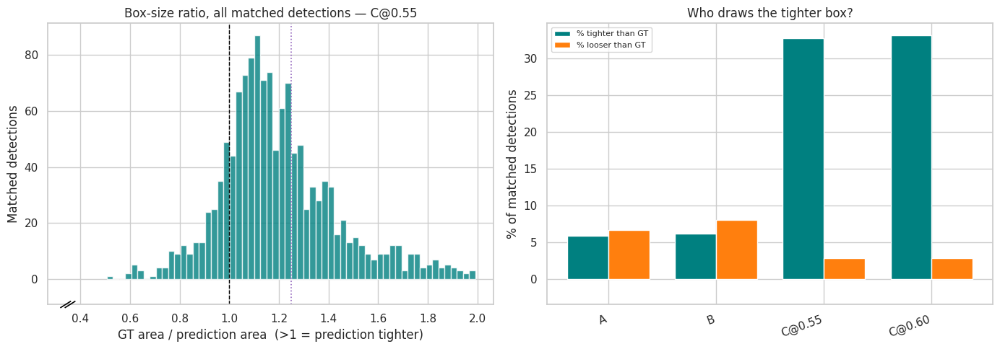


Tightness CSVs written to /content/drive/MyDrive/ExDark_dataset/phase2_results_yoloworld_v8


In [25]:
TIGHTER_MARGIN = 1.25   # GT at least 25% larger => prediction counted as tighter
CONTAIN_MIN    = 0.85   # prediction still substantially inside the GT box

def tightness_audit(tag, dataset_dir, cfg):
    """Compare box areas for every confident detection matched to a GT box."""
    test_dir = os.path.join(dataset_dir, "test")
    coco_gt = COCO(os.path.join(test_dir, "_annotations.coco.json"))
    ann = {a["id"]: a for a in coco_gt.loadAnns(coco_gt.getAnnIds())}
    df = EVAL[tag]["records"]
    d = df[(df.kind == "detection") & df.tp & (df.score >= 0.50) & df.gt_id.notna()]

    rows = []
    for r in d.itertuples():
        a = ann.get(int(r.gt_id))
        if a is None: continue
        b = a["bbox"]; gb = [b[0], b[1], b[0]+b[2], b[1]+b[3]]
        pb = [r.x1, r.y1, r.x2, r.y2]
        pa, ga = _area(pb), _area(gb)
        if pa <= 0 or ga <= 0: continue
        inter = _inter(pb, gb)
        ratio = ga / pa                       # >1 => GT larger => prediction tighter
        contain_pred = inter / pa
        contain_gt = inter / ga
        if ratio >= TIGHTER_MARGIN and contain_pred >= CONTAIN_MIN:
            verdict = "prediction tighter"
        elif (1 / ratio) >= TIGHTER_MARGIN and contain_gt >= CONTAIN_MIN:
            verdict = "prediction looser"
        else:
            verdict = "comparable"
        rows.append({"run": tag, "image_id": int(r.image_id), "file_name": r.file_name,
                     "cls": r.cls, "score": r.score, "iou": round(r.best_iou, 3),
                     "pred_area": round(pa, 1), "gt_area": round(ga, 1),
                     "area_ratio_gt_over_pred": round(ratio, 3),
                     "containment_pred_in_gt": round(contain_pred, 3),
                     "verdict": verdict,
                     "px1": pb[0], "py1": pb[1], "px2": pb[2], "py2": pb[3],
                     "gx1": gb[0], "gy1": gb[1], "gx2": gb[2], "gy2": gb[3]})
    return pd.DataFrame(rows)

TIGHT = {}
for tag in EVAL:
    t = tightness_audit(tag, RUN_CKPTS[tag]["dataset"], CFG)
    if len(t): TIGHT[tag] = t

if TIGHT:
    rows = []
    for tag, t in TIGHT.items():
        vc = t.verdict.value_counts()
        n = len(t)
        rows.append({"Run": tag, "matched_dets": n,
                     "tighter": int(vc.get("prediction tighter", 0)),
                     "looser": int(vc.get("prediction looser", 0)),
                     "comparable": int(vc.get("comparable", 0)),
                     "%tighter": round(100 * vc.get("prediction tighter", 0) / n, 1),
                     "%looser": round(100 * vc.get("prediction looser", 0) / n, 1),
                     "median_area_ratio": round(float(t.area_ratio_gt_over_pred.median()), 3)})
    TIGHT_SUMMARY = pd.DataFrame(rows)
    print("=== Prediction tighter vs looser than GT (matched detections) ===")
    display(TIGHT_SUMMARY)

    _t = TIGHT[_focus]
    net = (_t.verdict == "prediction tighter").sum() - (_t.verdict == "prediction looser").sum()
    print(f"\nFocus run: {_focus}  |  net tighter-minus-looser = {net:+d} "
          f"of {len(_t)} matched detections")
    print(f"  median GT/pred area ratio: {_t.area_ratio_gt_over_pred.median():.3f} "
          "(>1 means GT boxes are systematically larger)")

    print("\nPer-class tighter rate (which classes are most over-drawn in ExDark):")
    _pc = pd.DataFrame({
        "n": _t.cls.value_counts(),
        "tighter": _t[_t.verdict == "prediction tighter"].cls.value_counts(),
        "looser": _t[_t.verdict == "prediction looser"].cls.value_counts(),
        "median_ratio": _t.groupby("cls").area_ratio_gt_over_pred.median().round(3),
    }).fillna(0)
    _pc["%tighter"] = (100 * _pc.tighter / _pc.n).round(1)
    display(_pc.sort_values("%tighter", ascending=False))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ax = axes[0]
    ax.hist(_t.area_ratio_gt_over_pred.clip(0, 4), bins=60, color="teal", alpha=0.8)
    ax.axvline(1.0, ls="--", color="black", lw=1)
    ax.axvline(TIGHTER_MARGIN, ls=":", color="tab:purple", lw=1.2)
    ax.set_xlabel("GT area / prediction area  (>1 = prediction tighter)")
    ax.set_ylabel("Matched detections")
    ax.set_title(f"Box-size ratio, all matched detections — {_focus}")
    pad_for_break(ax); mark_axis_break(ax)

    ax = axes[1]
    xs = np.arange(len(TIGHT_SUMMARY)); w = 0.38
    ax.bar(xs - w/2, TIGHT_SUMMARY["%tighter"], w, label="% tighter than GT", color="teal")
    ax.bar(xs + w/2, TIGHT_SUMMARY["%looser"], w, label="% looser than GT", color="tab:orange")
    ax.set_xticks(xs); ax.set_xticklabels(TIGHT_SUMMARY["Run"], rotation=20, ha="right")
    ax.set_ylabel("% of matched detections"); ax.set_title("Who draws the tighter box?")
    ax.legend(fontsize=8)
    pad_for_break(ax, x=False); mark_axis_break(ax)
    plt.tight_layout(); savefig(fig, "tighter_than_gt.png"); plt.show()

    for tag, t in TIGHT.items():
        t.sort_values("area_ratio_gt_over_pred", ascending=False).to_csv(
            os.path.join(CFG.results_dir,
                         f"tightness_audit_{tag.replace('@','_').replace('.','')}.csv"), index=False)
    print(f"\nTightness CSVs written to {CFG.results_dir}")
else:
    print("[tightness] no matched detections to audit.")

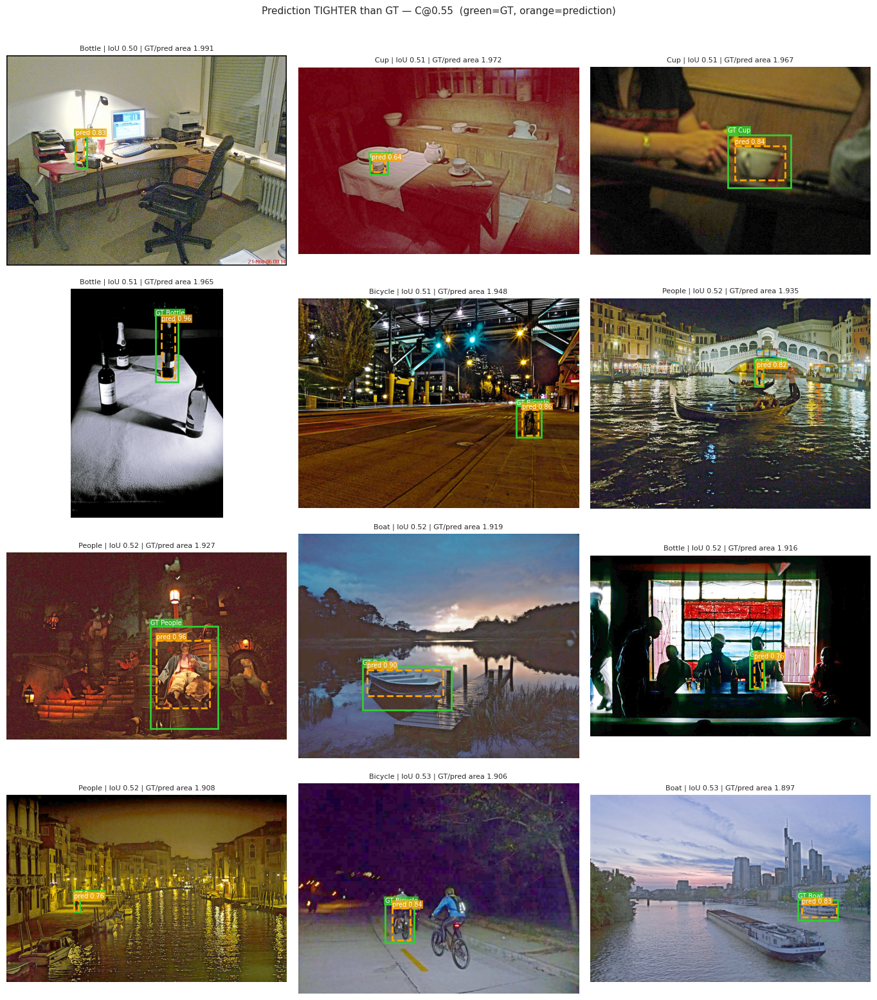

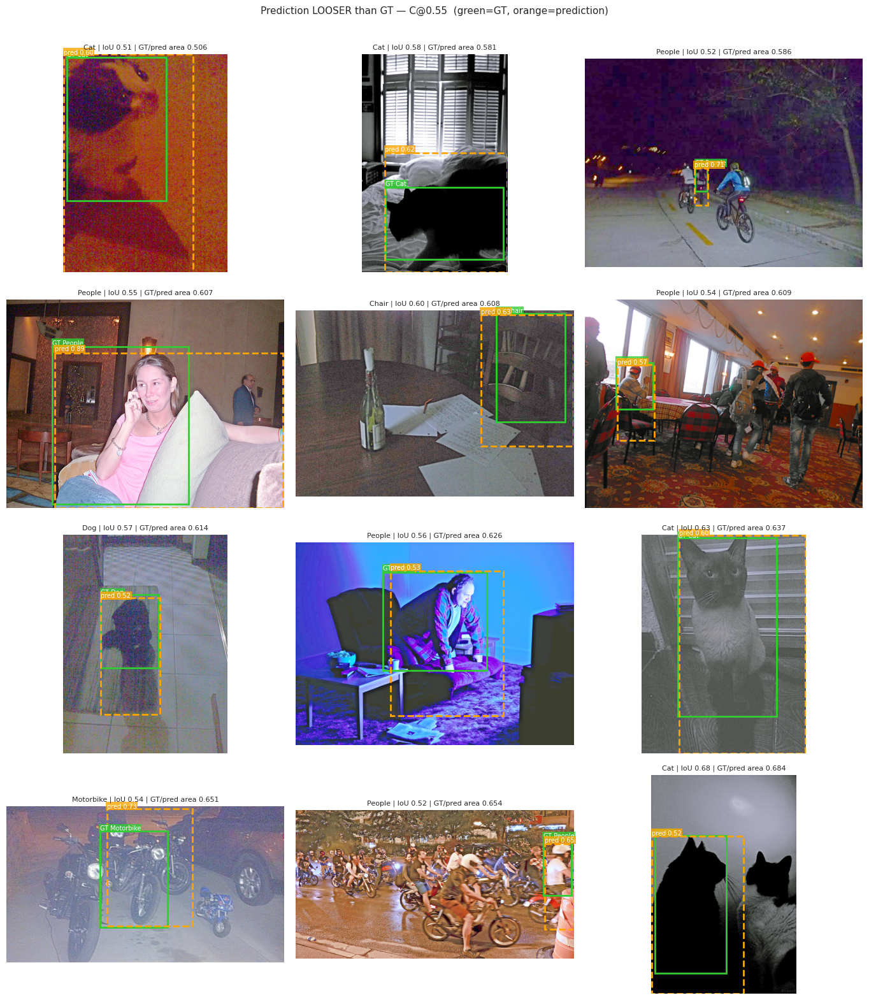

Most over-drawn GT boxes (largest GT/pred area ratio):


,file_name,cls,score,iou,pred_area,gt_area,area_ratio_gt_over_pred
666,Chair__2015_03801.png,Bottle,0.833000,0.502,590.7,1176.0,1.991
1312,Table__2015_07213.png,Cup,0.642223,0.507,1435.9,2832.0,1.972
800,Cup__2015_04558.png,Cup,0.840738,0.508,4363.5,8585.0,1.967
331,Bottle__2015_01833.png,Bottle,0.963562,0.509,26601.5,52269.0,1.965
132,Bicycle__2015_00621.png,Bicycle,0.864686,0.513,5429.8,10580.0,1.948
149,Boat__2015_00704.png,People,0.820318,0.517,475.5,920.0,1.935
905,Dog__2015_05237.png,People,0.963201,0.519,18738.8,36115.0,1.927
179,Boat__2015_00897.png,Boat,0.901280,0.521,5401.7,10366.0,1.919
238,Bottle__2015_01398.png,Bottle,0.763848,0.522,717.6,1375.0,1.916
159,Boat__2015_00770.png,People,0.763960,0.524,234.8,448.0,1.908


In [26]:
if TIGHT and _focus in TIGHT:
    _t = TIGHT[_focus]; _ds = RUN_CKPTS[_focus]["dataset"]

    render_cases(_t[_t.verdict == "prediction tighter"]
                 .sort_values("area_ratio_gt_over_pred", ascending=False),
                 _ds,
                 f"Prediction TIGHTER than GT — {_focus}  (green=GT, orange=prediction)",
                 "viz_pred_tighter_than_gt.png")

    render_cases(_t[_t.verdict == "prediction looser"]
                 .sort_values("area_ratio_gt_over_pred"),
                 _ds,
                 f"Prediction LOOSER than GT — {_focus}  (green=GT, orange=prediction)",
                 "viz_pred_looser_matched.png")

    _tt = _t[_t.verdict == "prediction tighter"]
    if len(_tt):
        print("Most over-drawn GT boxes (largest GT/pred area ratio):")
        display(_tt.sort_values("area_ratio_gt_over_pred", ascending=False)
                   [["file_name", "cls", "score", "iou",
                     "pred_area", "gt_area", "area_ratio_gt_over_pred"]].head(15))


ExDark labels the classes an image was *filed under*, so a photo in the `Car` folder may contain
unlabelled people, chairs or bottles. Detections of those objects are scored as false positives even
when they are correct, which depresses precision for reasons that have nothing to do with the model.

This finds images where confident detections substantially outnumber GT boxes, and isolates the
**orphan** detections — confident predictions with essentially no overlap against *any* GT box
(`best_iou <= orphan_iou_max`). Those are the candidates for unannotated objects.

Orphans are candidates, not proof: a confident detection of nothing is still a false positive. The
panels below are for eyeballing which it is, and the per-class table shows whether orphans concentrate
in the classes ExDark tends to leave unlabelled.


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
=== Over-detection summary ===


,Run,images,images_surplus>=2,pct_flagged,orphan_dets,orphans_of_unlabelled_class,mean_surplus
0,A,722,13,1.8,143,67,-0.41
1,B,734,18,2.5,150,69,-0.34
2,C@0.55,685,6,0.9,133,74,-0.81
3,C@0.60,683,4,0.6,103,66,-0.97



Focus run: C@0.55
  133 orphan detections; 74 are of a class with NO GT box in that image (strongest unannotated-object candidates)

Orphans by class (high counts = classes ExDark tends to leave unlabelled):


,orphans,of_unlabelled_class,median_conf
cls,,,
People,32,18.0,0.652
Chair,21,8.0,0.777
Car,18,6.0,0.625
Cup,17,11.0,0.869
Boat,10,5.0,0.577
Dog,9,8.0,0.558
Cat,9,9.0,0.650
Bottle,7,5.0,0.738
Bus,4,3.0,0.634


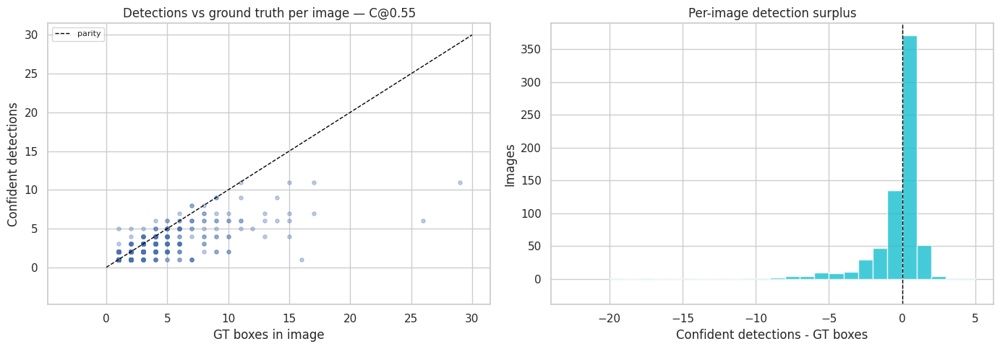


Over-detection CSVs written to /content/drive/MyDrive/ExDark_dataset/phase2_results_yoloworld_v8


In [18]:
ORPHAN_IOU_MAX  = 0.05    # no meaningful overlap with any GT box
ORPHAN_CONF_MIN = 0.50    # only confident detections count as candidates
SURPLUS_MIN     = 2       # image flagged when confident dets exceed GT by at least this many

def over_detection_audit(tag, dataset_dir, cfg):
    """Per-image detection-vs-GT counts, plus the orphan detections driving any surplus."""
    test_dir = os.path.join(dataset_dir, "test")
    coco_gt = COCO(os.path.join(test_dir, "_annotations.coco.json"))
    gt_count = {int(i): len(coco_gt.getAnnIds(imgIds=int(i))) for i in coco_gt.getImgIds()}
    gt_classes = {}
    id_to_name = {c["id"]: c["name"] for c in coco_gt.loadCats(coco_gt.getCatIds())}
    for i in coco_gt.getImgIds():
        gt_classes[int(i)] = {id_to_name.get(a["category_id"])
                              for a in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=int(i)))}

    df = EVAL[tag]["records"]
    d = df[(df.kind == "detection") & (df.score >= ORPHAN_CONF_MIN)]

    per_img, orphans = [], []
    for img_id, grp in d.groupby("image_id"):
        img_id = int(img_id)
        n_gt = gt_count.get(img_id, 0)
        n_det = len(grp)
        orph = grp[grp.best_iou <= ORPHAN_IOU_MAX]
        per_img.append({"run": tag, "image_id": img_id,
                        "file_name": grp.iloc[0].file_name,
                        "n_gt": n_gt, "n_conf_det": n_det,
                        "surplus": n_det - n_gt, "n_orphan": len(orph),
                        "orphan_classes": ",".join(sorted(set(orph.cls))) if len(orph) else "",
                        "gt_classes": ",".join(sorted(gt_classes.get(img_id, set())))})
        for r in orph.itertuples():
            orphans.append({"run": tag, "image_id": img_id, "file_name": r.file_name,
                            "cls": r.cls, "score": r.score, "best_iou": r.best_iou,
                            "in_gt_classes": r.cls in gt_classes.get(img_id, set()),
                            "px1": r.x1, "py1": r.y1, "px2": r.x2, "py2": r.y2})
    return pd.DataFrame(per_img), pd.DataFrame(orphans)

OVERDET, ORPHANS = {}, {}
for tag in EVAL:
    pi, orp = over_detection_audit(tag, RUN_CKPTS[tag]["dataset"], CFG)
    if len(pi):
        OVERDET[tag], ORPHANS[tag] = pi, orp

if OVERDET:
    summ = []
    for tag, pi in OVERDET.items():
        orp = ORPHANS[tag]
        flagged = pi[pi.surplus >= SURPLUS_MIN]
        summ.append({"Run": tag,
                     "images": len(pi),
                     f"images_surplus>={SURPLUS_MIN}": len(flagged),
                     "pct_flagged": round(100 * len(flagged) / len(pi), 1),
                     "orphan_dets": len(orp),
                     "orphans_of_unlabelled_class": int((~orp.in_gt_classes).sum()) if len(orp) else 0,
                     "mean_surplus": round(float(pi.surplus.mean()), 2)})
    OVERDET_SUMMARY = pd.DataFrame(summ)
    print("=== Over-detection summary ===")
    display(OVERDET_SUMMARY)

    _o = ORPHANS[_focus]; _p = OVERDET[_focus]
    print(f"\nFocus run: {_focus}")
    if len(_o):
        print(f"  {len(_o)} orphan detections; "
              f"{int((~_o.in_gt_classes).sum())} are of a class with NO GT box in that image "
              "(strongest unannotated-object candidates)")
        print("\nOrphans by class (high counts = classes ExDark tends to leave unlabelled):")
        _tab = pd.DataFrame({
            "orphans": _o.cls.value_counts(),
            "of_unlabelled_class": _o[~_o.in_gt_classes].cls.value_counts(),
            "median_conf": _o.groupby("cls").score.median().round(3),
        }).fillna(0).sort_values("orphans", ascending=False)
        display(_tab)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ax = axes[0]
    ax.scatter(_p.n_gt, _p.n_conf_det, s=14, alpha=0.35)
    lim = max(_p.n_gt.max(), _p.n_conf_det.max()) + 1
    ax.plot([0, lim], [0, lim], ls="--", color="black", lw=1, label="parity")
    ax.set_xlabel("GT boxes in image"); ax.set_ylabel("Confident detections")
    ax.set_title(f"Detections vs ground truth per image — {_focus}"); ax.legend(fontsize=8)
    pad_for_break(ax); mark_axis_break(ax)

    ax = axes[1]
    ax.hist(_p.surplus, bins=range(int(_p.surplus.min()), int(_p.surplus.max()) + 2),
            color="tab:cyan", alpha=0.8)
    ax.axvline(0, ls="--", color="black", lw=1)
    ax.set_xlabel("Confident detections - GT boxes"); ax.set_ylabel("Images")
    ax.set_title("Per-image detection surplus")
    pad_for_break(ax); mark_axis_break(ax)
    plt.tight_layout(); savefig(fig, "over_detection.png"); plt.show()

    for tag in OVERDET:
        safe = tag.replace("@", "_").replace(".", "")
        OVERDET[tag].sort_values("surplus", ascending=False).to_csv(
            os.path.join(CFG.results_dir, f"overdetection_{safe}.csv"), index=False)
        ORPHANS[tag].sort_values("score", ascending=False).to_csv(
            os.path.join(CFG.results_dir, f"orphan_detections_{safe}.csv"), index=False)
    print(f"\nOver-detection CSVs written to {CFG.results_dir}")
else:
    print("[overdet] no confident detections to audit.")


Renders the most over-detected images with **solid green = ground truth** and **dashed red = orphan
detections** (confident, no GT overlap). Where a red box lands squarely on a real object the annotators
skipped, that is a missing-label case rather than a model error.


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


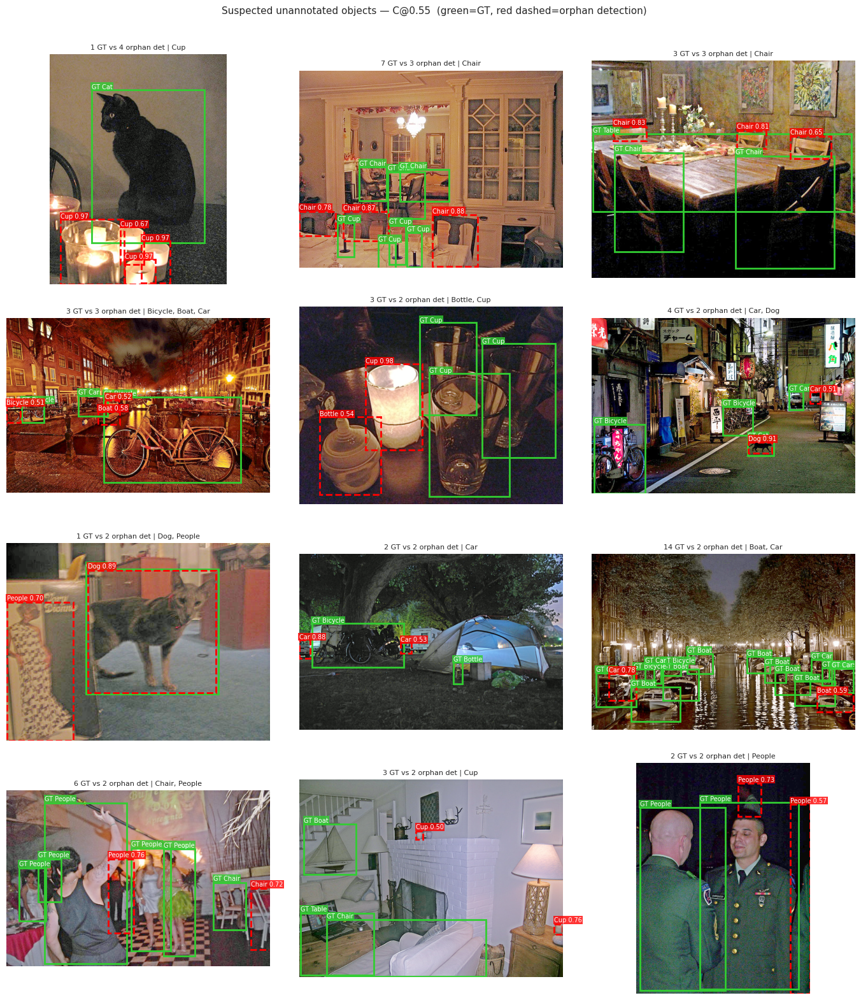

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


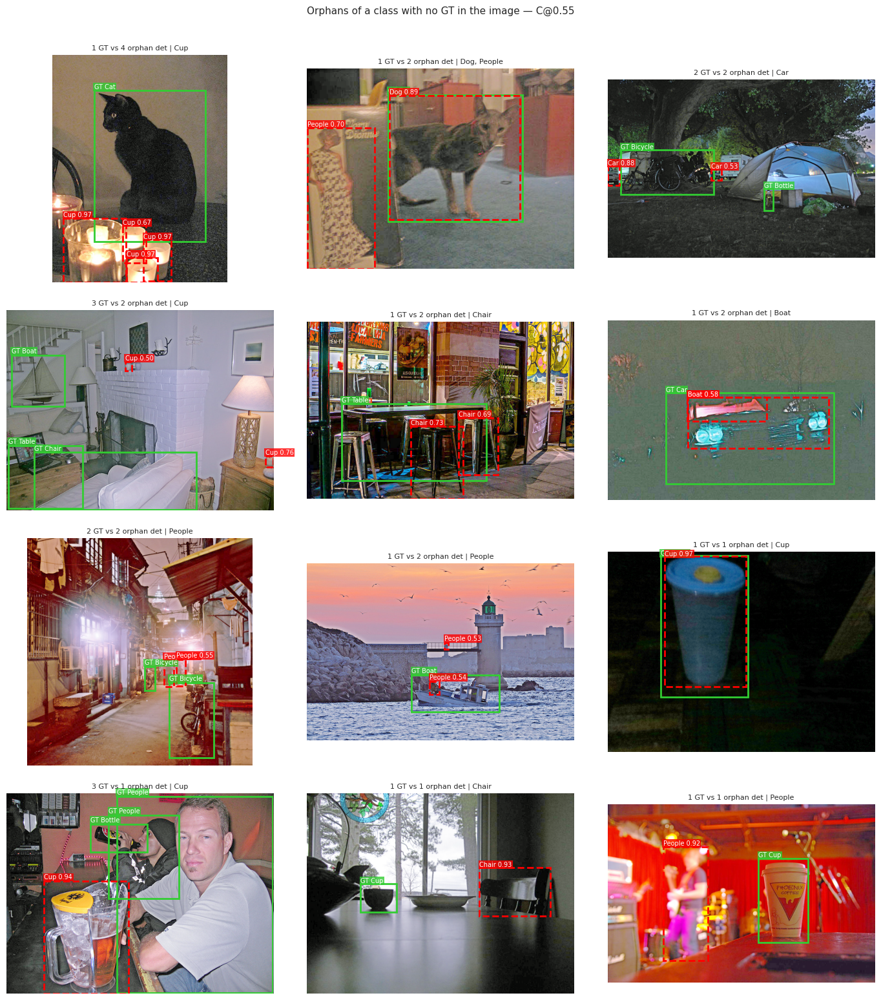


Highest-confidence orphans (inspect these first):


,file_name,cls,score,best_iou,in_gt_classes
97,Cup__2015_04816.png,Cup,0.976355,0.013329,True
64,Cat__2015_03650.png,Cup,0.974200,0.000000,False
65,Cat__2015_03650.png,Cup,0.973770,0.000000,False
30,Bottle__2015_01735.png,Cup,0.972246,0.000000,False
66,Cat__2015_03650.png,Cup,0.967819,0.000000,False
26,Bottle__2015_01425.png,Cup,0.936834,0.000000,False
35,Bus__2015_01906.png,Car,0.931405,0.014048,True
94,Cup__2015_04756.png,Chair,0.928774,0.000000,False
96,Cup__2015_04775.png,People,0.920878,0.000000,False
58,Cat__2015_03177.png,Dog,0.910171,0.000000,False


In [19]:
def render_orphans(orphan_df, per_img_df, dataset_dir, title, fname, n=N_PANELS):
    """One panel per image: all GT boxes in green, orphan detections in dashed red."""
    if not len(orphan_df):
        print(f"[viz] {title}: nothing to render"); return
    test_dir = os.path.join(dataset_dir, "test")
    coco_gt = COCO(os.path.join(test_dir, "_annotations.coco.json"))
    id_to_name = {c["id"]: c["name"] for c in coco_gt.loadCats(coco_gt.getCatIds())}

    # rank images by how many orphans they carry, then by top orphan confidence
    rank = (orphan_df.groupby("image_id")
            .agg(n_orphan=("cls", "size"), top=("score", "max"))
            .sort_values(["n_orphan", "top"], ascending=False).head(n))
    if not len(rank):
        print(f"[viz] {title}: nothing to render"); return

    rows = int(np.ceil(len(rank) / PANEL_COLS))
    fig, axes = plt.subplots(rows, PANEL_COLS, figsize=(4.6*PANEL_COLS, 3.9*rows))
    axes = np.atleast_1d(axes).flatten()
    for ax, (img_id, r) in zip(axes, rank.iterrows()):
        sub = orphan_df[orphan_df.image_id == img_id]
        fn = sub.iloc[0].file_name
        p = os.path.join(test_dir, fn)
        if not os.path.isfile(p):
            ax.axis("off"); continue
        boxes = []
        for a in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=int(img_id))):
            b = a["bbox"]
            boxes.append((f"GT {id_to_name.get(a['category_id'])}",
                          [b[0], b[1], b[0]+b[2], b[1]+b[3]], "limegreen", "-"))
        for o in sub.itertuples():
            boxes.append((f"{o.cls} {o.score:.2f}", [o.px1, o.py1, o.px2, o.py2], "red", "--"))
        n_gt = int(per_img_df[per_img_df.image_id == img_id].n_gt.iloc[0]) \
               if len(per_img_df[per_img_df.image_id == img_id]) else 0
        _draw(ax, Image.open(p).convert("RGB"), boxes,
              f"{n_gt} GT vs {int(r.n_orphan)} orphan det | {', '.join(sorted(set(sub.cls)))}")
    for ax in axes[len(rank):]:
        ax.axis("off")
    fig.suptitle(title, y=1.005, fontsize=11)
    plt.tight_layout(); savefig(fig, fname); plt.show()

if OVERDET and _focus in ORPHANS:
    _o, _p = ORPHANS[_focus], OVERDET[_focus]
    _ds = RUN_CKPTS[_focus]["dataset"]

    render_orphans(_o, _p, _ds,
                   f"Suspected unannotated objects — {_focus}  (green=GT, red dashed=orphan detection)",
                   "viz_orphan_detections.png")

    render_orphans(_o[~_o.in_gt_classes], _p, _ds,
                   f"Orphans of a class with no GT in the image — {_focus}",
                   "viz_orphan_unlabelled_class.png")

    if len(_o):
        print(f"\nHighest-confidence orphans (inspect these first):")
        display(_o.sort_values("score", ascending=False)
                  [["file_name", "cls", "score", "best_iou", "in_gt_classes"]].head(15))


## 11. Decision gates

Four questions, answered from the numbers rather than by eye. Gate 3 is the one Phase 1 could not
settle: its F1 optimum sat on the sweep boundary at 0.55, so only downstream mAP can say whether
coverage or purity actually wins.


In [21]:
def g(tag, key="mAP"):
    return (EVAL.get(tag, {}).get("metrics") or {}).get(key)

def gate(name, base, cand, verdict, eps=0.002):
    va, vb = g(base), g(cand)
    if va is None or vb is None:
        print(f"{name}: incomplete ({base}={va}, {cand}={vb})"); return None
    d = vb - va
    print(f"{name}: {cand}={vb:.4f} vs {base}={va:.4f}  (delta={d:+.4f}) -> {verdict(d, eps)}")
    return d

print("GATE 1 — Enhancement (B vs A)")
d1 = gate("  B vs A", "A", "B",
          lambda d, e: "enhancement HELPS" if d > e else ("enhancement HURTS" if d < -e else "NEUTRAL"))

print("\nGATE 2 — Distillation (best C vs B)")
_best_c = max([t for t in EVAL if t.startswith("C@") and not t.endswith("keepempty")],
              key=lambda t: g(t) or -1, default=None)
d2 = gate("  C vs B", "B", _best_c,
          lambda d, e: "pseudo-labels MATCH/BEAT human" if d > -0.005 else "pseudo-labels UNDERPERFORM") \
     if _best_c else None

print("\nGATE 3 — Threshold (C@0.55 vs C@0.60)")
d3 = gate("  0.55 vs 0.60", "C@0.60", "C@0.55",
          lambda d, e: "COVERAGE wins (lower threshold better)" if d > e
                       else ("PURITY wins (higher threshold better)" if d < -e else "INSENSITIVE"))

print("\nGATE 4 — Drop-empty (C@0.55 vs C@0.55_keepempty)")
d4 = gate("  drop vs keep", "C@0.55_keepempty", "C@0.55",
          lambda d, e: "dropping empties HELPS" if d > e
                       else ("dropping empties HURTS" if d < -e else "neutral"))

print("\nLOCALIZATION (tightness = mAP@[.5:.95] / mAP@0.5; lower => looser boxes)")
for tag in EVAL:
    m5, m = g(tag, "mAP50"), g(tag, "mAP")
    if m5 and m:
        print(f"  {tag:<20} mAP@0.5={m5:.3f}  mAP@[.5:.95]={m:.3f}  tightness={m/m5:.2f}")

print("\nOrdering (mAP@[.5:.95]):")
for tag, v in sorted([(t, g(t)) for t in EVAL if g(t) is not None], key=lambda x: -x[1]):
    print(f"  {tag:<20} {v:.4f}")

GATES = {"enhancement_B_minus_A": d1, "distillation_bestC_minus_B": d2,
         "threshold_C55_minus_C60": d3, "dropempty_minus_keepempty": d4,
         "best_C_run": _best_c}


GATE 1 — Enhancement (B vs A)
  B vs A: B=0.6208 vs A=0.6339  (delta=-0.0131) -> enhancement HURTS

GATE 2 — Distillation (best C vs B)
  C vs B: C@0.55=0.4203 vs B=0.6208  (delta=-0.2005) -> pseudo-labels UNDERPERFORM

GATE 3 — Threshold (C@0.55 vs C@0.60)
  0.55 vs 0.60: C@0.55=0.4203 vs C@0.60=0.4164  (delta=+0.0039) -> COVERAGE wins (lower threshold better)

GATE 4 — Drop-empty (C@0.55 vs C@0.55_keepempty)
  drop vs keep: incomplete (C@0.55_keepempty=None, C@0.55=0.4203)

LOCALIZATION (tightness = mAP@[.5:.95] / mAP@0.5; lower => looser boxes)
  A                    mAP@0.5=0.893  mAP@[.5:.95]=0.634  tightness=0.71
  B                    mAP@0.5=0.883  mAP@[.5:.95]=0.621  tightness=0.70
  C@0.55               mAP@0.5=0.758  mAP@[.5:.95]=0.420  tightness=0.55
  C@0.60               mAP@0.5=0.755  mAP@[.5:.95]=0.416  tightness=0.55

Ordering (mAP@[.5:.95]):
  A                    0.6339
  B                    0.6208
  C@0.55               0.4203
  C@0.60               0.4164


## 12. Persist results & the Phase 2b handoff

Writes metrics, per-class tables, gates, error profiles and the recommended hybrid thresholds to
`phase2_results_yoloworld_v8/`.


In [ ]:
os.makedirs(CFG.results_dir, exist_ok=True)
WRITTEN = []

def _save(df, name, **kw):
    """Write a CSV and record it, so the closing print lists this run's output only."""
    df.to_csv(os.path.join(CFG.results_dir, name), **kw)
    WRITTEN.append(name)

def _dump(obj, name):
    json.dump(obj, open(os.path.join(CFG.results_dir, name), "w"), indent=2, default=str)
    WRITTEN.append(name)

# Phase 1's prediction cache: a fixed path recorded for provenance, not a Phase 2 product.
PARQUET = os.path.join(CFG.drive_root, f"phase1_predictions_{RUN_TAG}", "train_predictions.parquet")

PHASE2 = {
    "run_tag": RUN_TAG,
    "config": {"epochs": CFG.epochs, "lr": CFG.lr, "batch_size": BATCH_SIZE,
               "grad_accum_steps": GRAD_ACCUM, "seed": CFG.seed,
               "resolution": CFG.resolution or 560, "run_plan": list(CFG.run_plan),
               "drop_empty_train": CFG.drop_empty_train, "iou_match": CFG.iou_match},
    "classes": CLASSES,
    "phase1_manifest": CFG.manifest_path,
    "teacher": M.get("teacher"),
    "dataset_stats": DS_STATS.to_dict(),
    "results": {t: {"metrics": e.get("metrics"), "params": e.get("params")} for t, e in EVAL.items()},
    "checkpoints": {t: i["best"] for t, i in RUN_CKPTS.items()},
    "gates": GATES,
    "detection_dumps": {t: e["dump"] for t, e in EVAL.items()},
    # Section 10 box-geometry table. Deliberately NOT named "tightness_audit": Phase 2b
    # and Phase 3a both have a dormant `if P2.get("tightness_audit")` branch that never
    # ran for the reported results, and reviving it here would change their output.
    "box_tightness": (TIGHT_SUMMARY.to_dict("records") if TIGHT else None),
    "over_detection": (OVERDET_SUMMARY.to_dict("records") if OVERDET else None),
}
_dump(PHASE2, "phase2_results.json")

_save(SUMMARY,      "phase2_summary.csv", index=False)
_save(PER_CLASS,    "phase2_per_class_ap.csv")
_save(PER_CLASS_50, "phase2_per_class_ap50.csv")
if TIGHT:
    _save(TIGHT_SUMMARY, "phase2_tightness_summary.csv", index=False)
if OVERDET:
    _save(OVERDET_SUMMARY, "phase2_over_detection_summary.csv", index=False)

HANDOFF = {
    "run_tag": RUN_TAG,
    "classes": CLASSES,
    "phase1_manifest": CFG.manifest_path,
    "pseudo_label_bank": M["pseudo_label_bank"],
    "enhanced_pool_dir": M["enhanced_pool_dir"],
    "prediction_cache": PARQUET if os.path.isfile(PARQUET) else None,
    "split_manifest": M.get("split_manifest"),
    "best_phase2_run": _best_c,
    "best_phase2_mAP": g(_best_c) if _best_c else None,
    "baseline_B_mAP": g("B"),
    "gates": GATES,
    "drop_empty_train": CFG.drop_empty_train,
    # Box geometry for the focus run. Both figures now come from the Section 10 tightness
    # audit (every matched detection, TIGHTER_MARGIN = 1.25) rather than the removed
    # low-IoU annotation audit, so they match the tightness table above.
    "pred_tighter_rate": (round(float((TIGHT[_focus].verdict == "prediction tighter").mean()), 3)
                          if TIGHT and _focus in TIGHT else None),
    "median_gt_pred_area_ratio": (round(float(TIGHT[_focus].area_ratio_gt_over_pred.median()), 3)
                                  if TIGHT and _focus in TIGHT else None),
    "orphan_detections": (int(len(ORPHANS[_focus])) if ORPHANS and _focus in ORPHANS else None),
    "orphans_of_unlabelled_class": (int((~ORPHANS[_focus].in_gt_classes).sum())
                                    if ORPHANS and _focus in ORPHANS and len(ORPHANS[_focus])
                                    else None),
    "weak_classes": [c for c in CLASSES
                     if _best_c and EVAL[_best_c]["metrics"]["per_class"].get(c, 1.0)
                     < 0.6 * float(pd.Series(EVAL[_best_c]["metrics"]["per_class"]).mean())],
    "results_dir": CFG.results_dir,
    "checkpoint_root": CFG.ckpt_root,
}
_dump(HANDOFF, "phase2_handoff.json")

print("Written by this cell ->", CFG.results_dir)
for f in WRITTEN:
    print("  +", f)
_other = sorted(set(os.listdir(CFG.results_dir)) - set(WRITTEN))
if _other:
    print("\nAlso in the folder (detection dumps, tightness CSVs, or files from an earlier run):")
    for f in _other:
        print("  -", f)
print("\nGates:", json.dumps(GATES, indent=2, default=str))

Saved to /content/drive/MyDrive/ExDark_dataset/phase2_results_yoloworld_v8
  - annotation_audit.png
  - annotation_audit_A.csv
  - annotation_audit_B.csv
  - annotation_audit_C_055.csv
  - annotation_audit_C_060.csv
  - annotation_audit_all_runs.csv
  - band_precision_heatmap.png
  - convergence_curves.png
  - detections_A.parquet
  - detections_B.parquet
  - detections_C_055.parquet
  - detections_C_060.parquet
  - error_analysis.png
  - inspect_low_conf_A.csv
  - inspect_low_conf_B.csv
  - inspect_low_conf_C_055.csv
  - inspect_low_conf_C_060.csv
  - inspect_low_iou_A.csv
  - inspect_low_iou_B.csv
  - inspect_low_iou_C_055.csv
  - inspect_low_iou_C_060.csv
  - inspect_missed_gt_A.csv
  - inspect_missed_gt_B.csv
  - inspect_missed_gt_C_055.csv
  - inspect_missed_gt_C_060.csv
  - orphan_detections_A.csv
  - orphan_detections_B.csv
  - orphan_detections_C_055.csv
  - orphan_detections_C_060.csv
  - over_detection.png
  - overdetection_A.csv
  - overdetection_B.csv
  - overdetection_C_05